# Mean density plot as a function of radius and phase diagram

In [25]:
import yt
yt.set_log_level(50)
import unyt
from astropy.table import Table
import helper_functions as hf
import numpy as np
import matplotlib.pyplot as plt

# Load the simulation data

In [26]:
df='/lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine'

target_sink=36

In [27]:
# Snapshot number
output=59

In [28]:
ds=yt.load(hf.info_file(output,df))

ad=ds.all_data(); # Load a data object that contains all data

Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00059/info_00059.txt


In [5]:
# Load position from file at this output
filename=f'{df}/output_{str(output).zfill(5)}/sink_{str(output).zfill(5)}.csv'
t = Table.read(filename,format='ascii',names=['sink_id','BHmass','x','y','z','vx','vy','vz','tsink','dMdt'])
print("This output contains",len(t),"black holes")

This output contains 660 black holes


In [6]:
# Find position of target BH
sink_pos=t[t['sink_id']==target_sink]['x','y','z'] # Position on 6th sink
sink_pos_ds=ds.arr(sink_pos[0].as_void().tolist(),'code_length') #Position converted to something the dataset understands by adding units and stripping formatting
print(sink_pos_ds)

[0.5041326  0.50041442 0.50459845] code_length


In [6]:
sp = ds.sphere(sink_pos_ds, ds.quan(5, 'kpc'))

# Phase Diagram


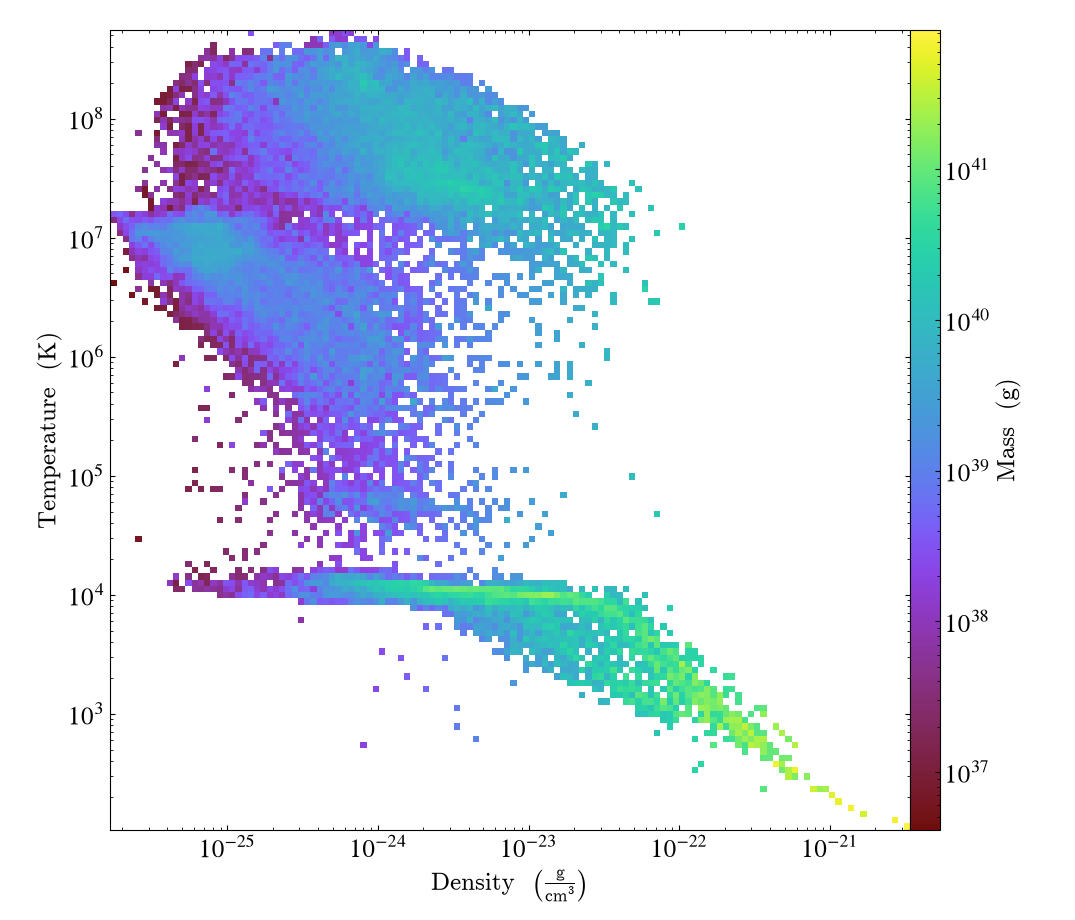

In [ ]:
plot = yt.PhasePlot(
    sp, ("gas", "density"), ("gas", "temperature"), [("gas", "mass")], weight_field=None
)

# plot.save("fig/phase_1_1.png")
plot.show()

# Volume Weighted radial density profile

Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00105/info_00105.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00106/info_00106.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00107/info_00107.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00108/info_00108.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00109/info_00109.txt



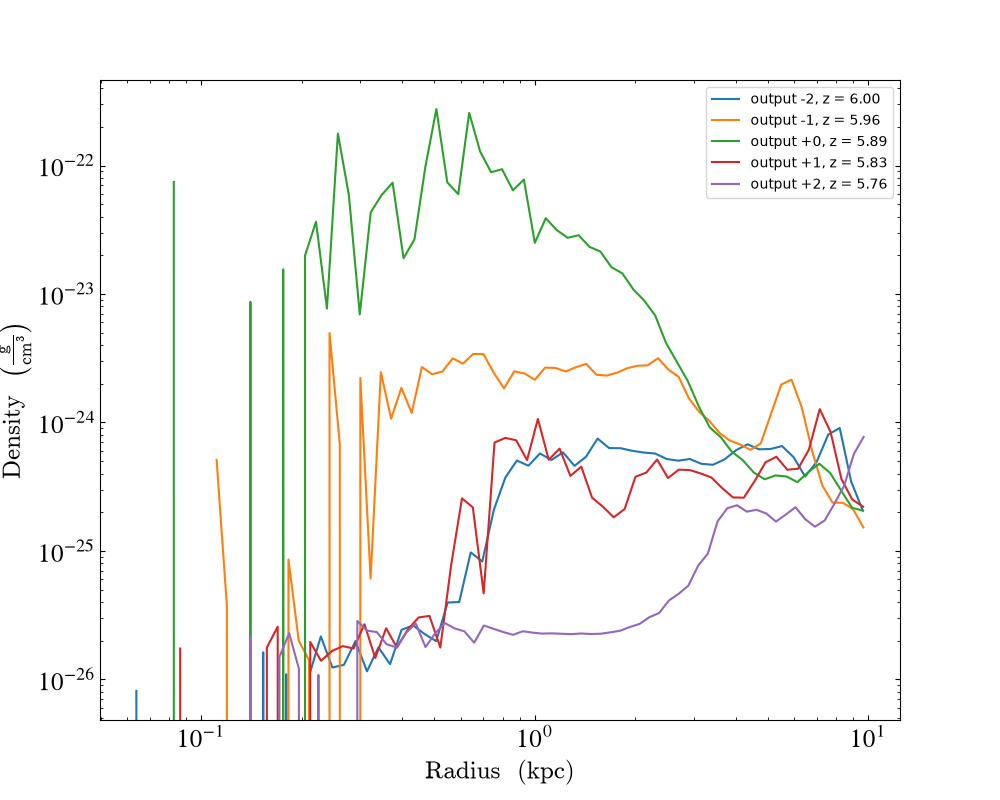

In [8]:
outputs = range(output - 2, output + 3)

profiles, labels = [], []
for out in outputs:
    ds = yt.load(hf.info_file(out, df))

    filename=f'{df}/output_{str(out).zfill(5)}/sink_{str(out).zfill(5)}.csv'
    t = Table.read(filename,format='ascii',names=['sink_id','BHmass','x','y','z','vx','vy','vz','tsink','dMdt'])

    sink_pos=t[t['sink_id']==target_sink]['x','y','z']
    sink_pos_ds=ds.arr(sink_pos[0].as_void().tolist(),'code_length')

    sp = ds.sphere(sink_pos_ds, ds.quan(10, 'kpc'))

    profiles.append(
        yt.create_profile(
            sp,
            [("index", "radius")],
            [("gas", "density")],
            weight_field= ("gas", "cell_volume"),
            units={("index", "radius"): "kpc"}
        )
    )

    labels.append(f'output {out - output:+d}, z = {ds.current_redshift:.2f}')
plot = yt.ProfilePlot.from_profiles(profiles, labels=labels)
plot.set_unit(('index', 'radius'), 'kpc')

plot.show()
# plot.save("fig/radial_profile/most_massive_volume_2.png")

# Mass weighted radial density profile

Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00105/info_00105.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00106/info_00106.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00107/info_00107.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00108/info_00108.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00109/info_00109.txt



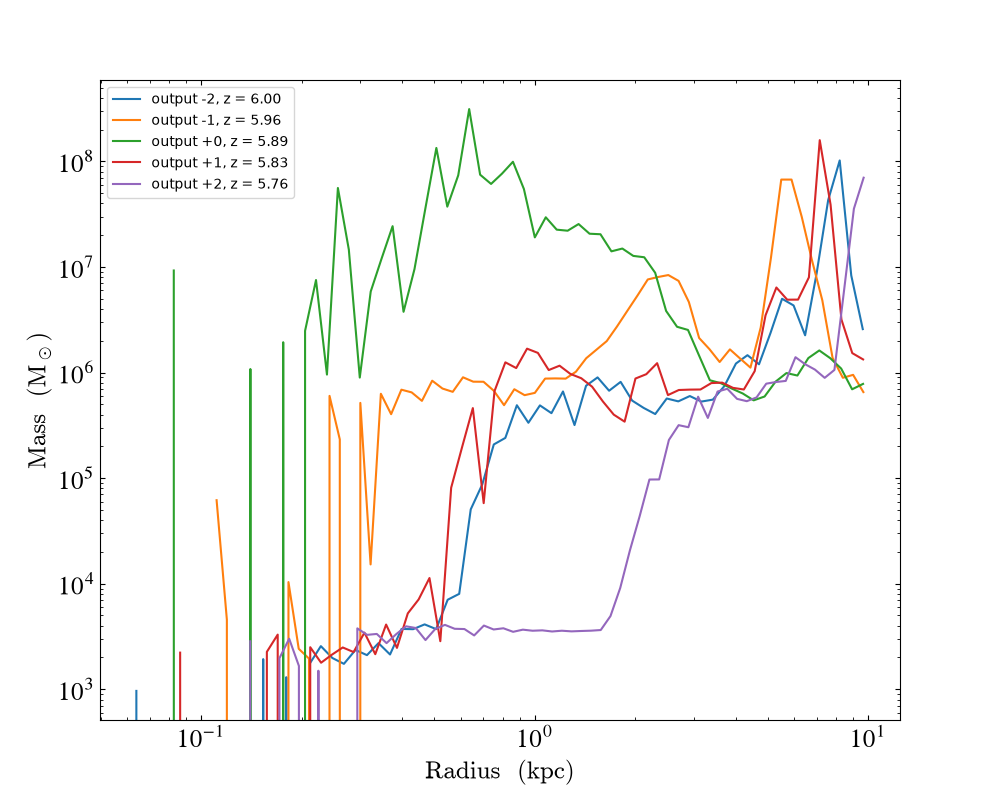

In [9]:
outputs = range(output - 2, output + 3)

profiles, labels = [], []
for out in outputs:
    ds = yt.load(hf.info_file(out, df))

    filename=f'{df}/output_{str(out).zfill(5)}/sink_{str(out).zfill(5)}.csv'
    t = Table.read(filename,format='ascii',names=['sink_id','BHmass','x','y','z','vx','vy','vz','tsink','dMdt'])

    sink_pos=t[t['sink_id']==target_sink]['x','y','z']
    sink_pos_ds=ds.arr(sink_pos[0].as_void().tolist(),'code_length')

    sp = ds.sphere(sink_pos_ds, ds.quan(10, 'kpc'))

    profiles.append(
        yt.create_profile(
            sp,
            [("index", "radius")],
            [("gas", "mass")],
            weight_field= ("gas", "mass"),
            units={("index", "radius"): "kpc"}
        )
    )

    labels.append(f'output {out - output:+d}, z = {ds.current_redshift:.2f}')
plot = yt.ProfilePlot.from_profiles(profiles, labels=labels)
plot.set_unit(('index', 'radius'), 'kpc')
plot.set_unit(('gas', 'mass'), 'Msun')

plot.show()
# plot.save("fig/radial_profile/most_massive_mass_2.png")

# Accumulated Mass

Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00105/info_00105.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00106/info_00106.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00107/info_00107.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00108/info_00108.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00109/info_00109.txt



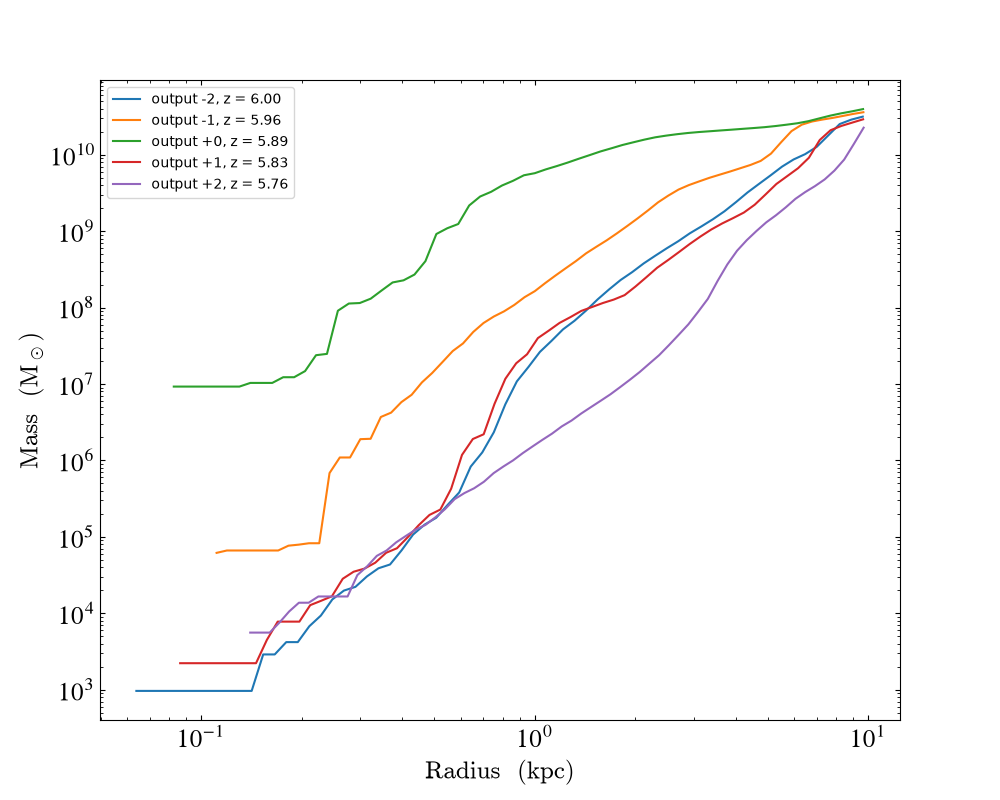

In [10]:
outputs = range(output - 2, output + 3)

profiles, labels = [], []
for out in outputs:
    ds = yt.load(hf.info_file(out, df))

    filename=f'{df}/output_{str(out).zfill(5)}/sink_{str(out).zfill(5)}.csv'
    t = Table.read(filename,format='ascii',names=['sink_id','BHmass','x','y','z','vx','vy','vz','tsink','dMdt'])

    sink_pos=t[t['sink_id']==target_sink]['x','y','z']
    sink_pos_ds=ds.arr(sink_pos[0].as_void().tolist(),'code_length')

    sp = ds.sphere(sink_pos_ds, ds.quan(10, 'kpc'))

    profiles.append(
        yt.create_profile(
            sp,
            [("index", "radius")],
            [("gas", "mass")],
            weight_field= None,
            units={("index", "radius"): "kpc"},
            accumulation=True
        )
    )

    labels.append(f'output {out - output:+d}, z = {ds.current_redshift:.2f}')
plot = yt.ProfilePlot.from_profiles(profiles, labels=labels)
plot.set_unit(('index', 'radius'), 'kpc')
plot.set_unit(('gas', 'mass'), 'Msun')

plot.show()
# plot.save('fig/radial_profile/most_massive_accumlation_2.png')

# Density vs time at a fixed radius

In [36]:
output = 100
target_sink=5

In [37]:
ts   = hf.SinkDataLoader(df, sinkid=target_sink)
time = Table.read(df+'/ADAPTAclump_maps/output_step_redshift.txt', format='ascii')
snap_t   = np.array([float(t) for t in time['time']])
snap_out = np.array([int(o) for o in time['output']])

win = (snap_out >= output - 10) & (snap_out <= output + 10)

In [38]:
rho_rt, t_list = [], []
for out, t_out in zip(snap_out[win], snap_t[win]):
    ds  = yt.load(hf.info_file(out, df))
    filename=f'{df}/output_{str(out).zfill(5)}/sink_{str(out).zfill(5)}.csv'
    t = Table.read(filename,format='ascii',names=['sink_id','BHmass','x','y','z','vx','vy','vz','tsink','dMdt'])
    sel = t[t['sink_id'] == target_sink]
    c  = ds.arr(sel['x','y','z'][0].as_void().tolist(), 'code_length')
    sp = ds.sphere(c, (10, 'kpc'))
    prof = yt.create_profile(sp, [("index","radius")], [("gas","density")],
                             weight_field=("gas","cell_volume"),
                             units={("index","radius"):"kpc"},
                             extrema={("index","radius"):(0.1, 10)},
                             n_bins=64, logs={("index","radius"):True})
    rho = prof[("gas","density")].to('g/cm**3').v
    rho[~prof.used] = np.nan
    rho_rt.append(rho)
    t_list.append(t_out)

r_bins = prof.x.to('kpc').v
rho_rt = np.array(rho_rt)
t_list = np.array(t_list);

Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00090/info_00090.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00091/info_00091.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00092/info_00092.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00093/info_00093.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00094/info_00094.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00095/info_00095.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00096/info_00096.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00097/info_00097.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00098/info_00098.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00099/info_00099.txt
Opening /l

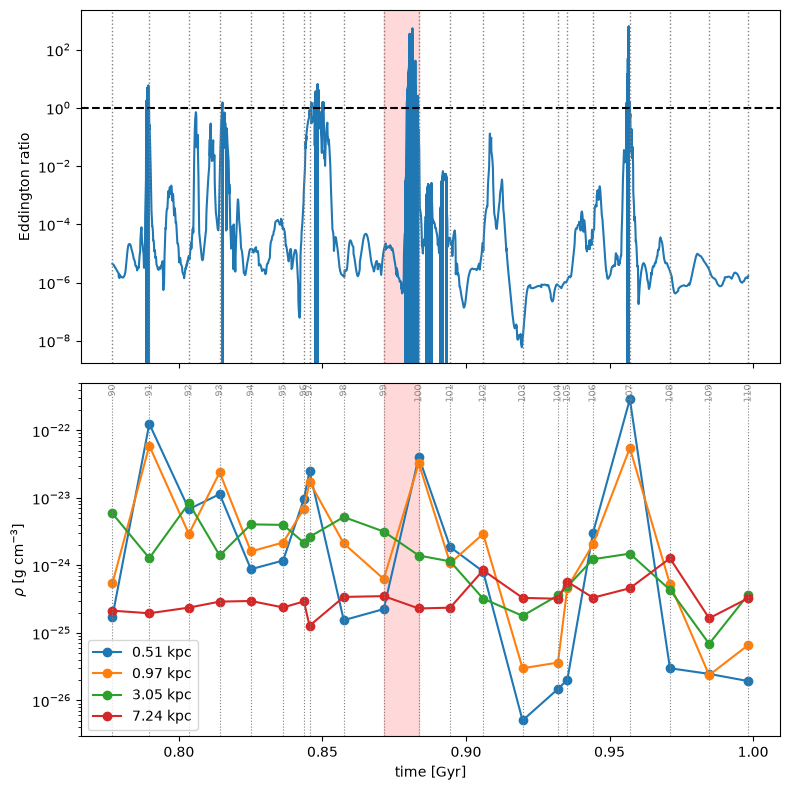

In [ ]:
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(8, 8))
times = ts.data['time'].to('Gyr').value
m = (times > t_list[0]) & (times < t_list[-1])
axes[0].semilogy(times[m], (ts.data['dotMaccr']/ts.data['dotMedd'])[m])
axes[0].axhline(1, ls='--', c='k')
axes[0].set_ylabel('Eddington ratio')

output_labels = [str(o) for o in snap_out[win]]

for r0 in [0.5, 1.0, 3.0, 7.5]:
    j = np.argmin(np.abs(r_bins - r0))
    axes[1].semilogy(t_list, rho_rt[:, j], 'o-', label=f'{r_bins[j]:.2f} kpc')

t_before, t_target = snap_t[snap_out == output - 1][0], snap_t[snap_out == output][0]

axes[0].axvspan(t_before, t_target, color='r', alpha=0.15)
axes[1].axvspan(t_before, t_target, color='r', alpha=0.15)

ymin1, ymax1 = axes[1].get_ylim()
label_y = ymax1 * 0.95

for tt, label in zip(t_list, output_labels): 
    axes[0].axvline(tt, color='grey', ls=':', lw=1)
    axes[1].axvline(tt, color='grey', ls=':', lw=0.8)
    axes[1].text(tt, label_y, label, color='grey', fontsize=7, rotation=90, va='top', ha='center', alpha=0.8)

axes[1].set_ylabel(r'$\rho$ [g cm$^{-3}$]') 
axes[1].set_xlabel('time [Gyr]')
axes[1].legend()
plt.tight_layout()
# plt.savefig("fig/density_time_1");